# Rush 4 – Segmentation des utilisateurs Instagram

**Objectif :** regrouper les volontaires en familles d'usage, puis décrire ces familles avec les indicateurs de bien-être.

**Règles éthiques suivies dans ce notebook :**
- aucune ligne individuelle n'est affichée, seulement des résultats agrégés ;
- les données de santé servent à **décrire** les familles, jamais à les **construire** ;
- les noms des familles décrivent des comportements, pas des états de santé ;
- les démonstrations utilisent uniquement des profils fictifs.

## Problématique

**Question :** le style d'usage d'Instagram permet-il de distinguer des familles d'utilisateurs utiles aux équipes produit, et ces familles disent-elles quelque chose du bien-être que le seul temps passé ne dit pas ?

**Critères de réussite, fixés avant l'analyse et vérifiés en section 9 :**
1. familles distinctes (silhouette ≥ 0,15) ;
2. familles stables (ARI ≥ 0,90) ;
3. taille exploitable (plus petite famille ≥ 10 %) ;
4. à 6. aucune famille ne cible les mineurs, un genre ou un pays (écarts ≤ 2 à 3 points) ;
7. apport sur le bien-être supérieur à un simple classement par temps passé.

**Ce que les données ne permettront pas de conclure :** une relation de cause à effet (les données sont relevées à une seule date), une généralisation du panel de volontaires à tous les utilisateurs, et une transposition directe de la réplique synthétique aux utilisateurs réels.

In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, r2_score, mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, cross_val_predict

RANDOM_STATE = 42
CHEMIN = "data/instagram_users_lifestyleSafe.csv"
CHEMIN_BRUT = "data/instagram_usage_lifestyleSafe.csv"

In [64]:
df = pd.read_csv(CHEMIN)
print(df.shape)

(200000, 58)


## 1. Choix du fichier

In [66]:
brut = pd.read_csv(CHEMIN_BRUT)
a = df.sort_values("user_id").reset_index(drop=True)
b = brut.sort_values("user_id").reset_index(drop=True)
print("Mêmes utilisateurs dans les deux fichiers :", a["user_id"].equals(b["user_id"]))

differences = pd.Series({col: (a[col] != b[col]).sum() for col in a.columns})
print("Colonnes identiques pour un même user_id :", (differences == 0).sum(), "sur", len(differences))
differences[differences > 0].sort_values(ascending=False)

Mêmes utilisateurs dans les deux fichiers : True
Colonnes identiques pour un même user_id : 52 sur 58


account_creation_year    31772
employment_status        18913
weekly_work_hours        18912
relationship_status       6623
has_children              5329
education_level           1203
dtype: int64

In [67]:
def incoherences_mineurs(table):
    mineur = table["age"] < 18
    return pd.Series({
        "mineurs avec un emploi": (mineur & ~table["employment_status"].isin(["Student", "Not employed", "Unemployed"])).sum(),
        "mineurs avec des heures de travail": (mineur & (table["weekly_work_hours"] > 0)).sum(),
        "mineurs mariés, divorcés ou veufs": (mineur & table["relationship_status"].isin(["Married", "Divorced", "Widowed"])).sum(),
        "mineurs avec des enfants": (mineur & (table["has_children"] == "Yes")).sum(),
        "mineurs titulaires d'un diplôme du supérieur": (mineur & table["education_level"].isin(["Bachelor’s", "Master’s", "PhD"])).sum(),
    })

pd.DataFrame({"fichier brut (usage)": incoherences_mineurs(brut),
              "fichier corrigé (users)": incoherences_mineurs(df)})

,fichier brut (usage),fichier corrigé (users)
mineurs avec un emploi,12847,0
mineurs avec des heures de travail,18912,0
"mineurs mariés, divorcés ou veufs",6623,0
mineurs avec des enfants,5329,0
mineurs titulaires d'un diplôme du supérieur,9403,8828


In [68]:
def controle_dates(table):
    annee_connexion = pd.to_datetime(table["last_login_date"]).dt.year
    age_creation = table["account_creation_year"] - (annee_connexion - table["age"])
    return pd.Series({
        "compte créé après la dernière connexion": (table["account_creation_year"] > annee_connexion).sum(),
        "compte créé avant 13 ans": (age_creation < 13).sum(),
    })

resultat = pd.DataFrame({"fichier brut (usage)": controle_dates(brut),
                         "fichier corrigé (users)": controle_dates(df)})
del brut, a, b
resultat

,fichier brut (usage),fichier corrigé (users)
compte créé après la dernière connexion,0,3724
compte créé avant 13 ans,27989,0


**Décision : nous travaillons avec le fichier `users`.** Les deux fichiers contiennent les mêmes 200 000 utilisateurs, et seules 6 colonnes diffèrent. Le fichier `users` corrige les incohérences du fichier brut : plus aucun mineur n'a d'emploi, de conjoint ou d'enfant, et plus aucun compte n'a été créé avant 13 ans.

**Ce qui reste imparfait :** 8 828 mineurs ont encore un diplôme du supérieur, et 3 724 comptes ont été créés après leur dernière connexion. Ces colonnes ne servent pas à construire les familles, donc ces défauts ne faussent pas la segmentation.

**Confiance accordée à chaque colonne qui diffère entre les deux fichiers :**

| Colonne | Fichier retenu | Raison |
|---|---|---|
| `employment_status` | users | le brut compte 12 847 mineurs avec un emploi |
| `weekly_work_hours` | users | le brut compte 18 912 mineurs déclarant des heures de travail |
| `relationship_status` | users | le brut compte 6 623 mineurs mariés, divorcés ou veufs |
| `has_children` | users | le brut compte 5 329 mineurs avec des enfants |
| `education_level` | users, avec réserve | 8 828 mineurs restent diplômés du supérieur ; colonne non utilisée pour les familles |
| `account_creation_year` | **aucun n'est fiable** | brut : 27 989 comptes créés avant 13 ans ; users : 3 724 comptes créés après la dernière connexion. Utilisée seulement pour le contrôle de l'âge minimal, dont le résultat reste une estimation. |

## 2. Contrôle qualité

In [69]:
print("Valeurs manquantes :", df.isna().sum().sum())
print("Utilisateurs en double :", df["user_id"].duplicated().sum())
print("Clics pub supérieurs aux pubs vues :", (df["ads_clicked_per_day"] > df["ads_viewed_per_day"]).sum())

temps_sections = df[["time_on_feed_per_day", "time_on_explore_per_day", "time_on_messages_per_day", "time_on_reels_per_day"]].sum(axis=1)
print("Écart moyen entre temps total et somme des sections (min) :", round((df["daily_active_minutes_instagram"] - temps_sections).abs().mean(), 1))

Valeurs manquantes : 0
Utilisateurs en double : 0
Clics pub supérieurs aux pubs vues : 628
Écart moyen entre temps total et somme des sections (min) : 33.9


In [70]:
annee_connexion = pd.to_datetime(df["last_login_date"]).dt.year
age_creation = df["account_creation_year"] - (annee_connexion - df["age"])

coree = (df["country"] == "South Korea") & (age_creation < 14)
australie = (df["country"] == "Australia") & (age_creation < 16) & (df["account_creation_year"] >= 2026)
a_retirer = coree | australie

print("Corée du Sud, compte créé avant 14 ans :", coree.sum())
print("Australie, compte créé avant 16 ans en 2026 :", australie.sum())
print("Australiens ayant aujourd'hui moins de 16 ans :", ((df["country"] == "Australia") & (df["age"] < 16)).sum())

df = df[~a_retirer].reset_index(drop=True)
print("Profils retirés :", a_retirer.sum(), "| Utilisateurs restants :", len(df))

Corée du Sud, compte créé avant 14 ans : 14
Australie, compte créé avant 16 ans en 2026 : 213
Australiens ayant aujourd'hui moins de 16 ans : 671
Profils retirés : 227 | Utilisateurs restants : 199773


**Résultats.** Le fichier ne contient ni valeur manquante ni doublon. Deux incohérences propres à la réplique synthétique subsistent : 628 utilisateurs cliquent sur plus de publicités qu'ils n'en voient, et le temps total quotidien diffère en moyenne de 34 minutes de la somme des temps par section.

**Âge minimal par pays.** Nous retirons par précaution 227 profils (0,11 % du fichier) : 14 Sud-Coréens ayant créé leur compte avant 14 ans, et 213 Australiens l'ayant créé avant 16 ans depuis l'entrée en vigueur de la loi australienne (10 décembre 2025). Il s'agit de mineurs, dans une étude sur la santé mentale : le principe de minimisation justifie de ne pas traiter leurs données. **L'analyse porte donc sur 199 773 utilisateurs.**

**Point d'alerte.** 671 Australiens ont aujourd'hui moins de 16 ans : ils devront être exclus de tout ciblage réel. **Limite :** le fichier ne donne que l'année de création du compte, donc l'âge à la création est estimé à un an près.

## 2 bis. Exploration des profils

In [71]:
df["tranche_age"] = pd.cut(df["age"], bins=[0, 17, 25, 35, 45, 55, 120],
    labels=["moins de 18 ans", "18-25 ans", "26-35 ans", "36-45 ans", "46-55 ans", "56 ans et plus"])

print(df.groupby("tranche_age", observed=True).agg(
    utilisateurs=("age", "size"),
    temps_moyen=("daily_active_minutes_instagram", "mean"),
    stress_moyen=("perceived_stress_score", "mean")).round(1))
print()
for variable in ["gender", "country", "urban_rural", "income_level", "employment_status"]:
    moyennes = df.groupby(variable)["daily_active_minutes_instagram"].mean()
    print(f"{variable} : de {moyennes.min():.0f} à {moyennes.max():.0f} minutes par jour")

                 utilisateurs  temps_moyen  stress_moyen
tranche_age                                             
moins de 18 ans         18693        222.7          20.0
18-25 ans               30004        214.5          20.1
26-35 ans               38224        200.7          20.0
36-45 ans               37751        186.8          20.0
46-55 ans               37508        171.6          20.0
56 ans et plus          37593        158.0          20.0

gender : de 187 à 193 minutes par jour
country : de 187 à 191 minutes par jour
urban_rural : de 188 à 189 minutes par jour
income_level : de 188 à 189 minutes par jour
employment_status : de 182 à 223 minutes par jour


**Lecture.** L'âge est le seul trait de profil fortement lié au temps passé : 223 minutes par jour chez les moins de 18 ans, contre 158 chez les 56 ans et plus. Le genre, le pays, le milieu et le revenu font varier ce temps de moins de 6 minutes. L'écart selon l'emploi (182 à 223 minutes) reflète surtout l'âge des étudiants.

**Un résultat surprenant :** les plus jeunes passent 65 minutes de plus par jour sur Instagram, mais leur stress moyen est **identique** (20,0 dans toutes les tranches). Si le temps passé provoquait mécaniquement le stress, les jeunes seraient plus stressés. Ce n'est pas le cas : c'est un premier signal qu'association ne veut pas dire causalité.

## 3. Choix des colonnes

Nous appliquons trois filtres successifs : **la loi** (RGPD), **la redondance** (une colonne qui répète le temps passé n'apporte rien), puis **le style d'usage** (des ratios qui décrivent *comment* on utilise Instagram, et non *combien*).

### Filtre 1 : le RGPD

In [72]:
EXCLUES_RGPD = {
    "santé (article 9 du RGPD)": ["exercise_hours_per_week", "sleep_hours_per_night", "diet_quality", "smoking",
        "alcohol_frequency", "perceived_stress_score", "self_reported_happiness", "body_mass_index",
        "blood_pressure_systolic", "blood_pressure_diastolic", "daily_steps_count"],
    "vie privée (hors finalité)": ["income_level", "employment_status", "education_level", "relationship_status",
        "has_children", "weekly_work_hours", "hobbies_count", "social_events_per_month", "books_read_per_year",
        "volunteer_hours_per_month", "travel_frequency_per_year"],
    "profil sensible (risque de discrimination)": ["age", "gender", "country", "urban_rural"],
}

for categorie, colonnes in EXCLUES_RGPD.items():
    print(f"{categorie} : {len(colonnes)} colonnes")
print("Total exclu de la construction des familles :", sum(len(c) for c in EXCLUES_RGPD.values()), "colonnes")

santé (article 9 du RGPD) : 11 colonnes
vie privée (hors finalité) : 11 colonnes
profil sensible (risque de discrimination) : 4 colonnes
Total exclu de la construction des familles : 26 colonnes


**Pourquoi ces colonnes ne construisent pas les familles.** Les volontaires ont accepté une étude sur le bien-être, pas un profilage. Or nos familles sont destinées aux équipes produit, qui les appliqueront à de vrais utilisateurs : elles ne doivent reposer que sur des données d'usage. Les données de santé servent donc uniquement à décrire les familles. Les données de vie privée sont hors sujet. L'âge, le genre et le pays servent seulement à vérifier qu'aucune famille ne cible un groupe protégé.

### Filtre 2 : la redondance

In [73]:
CANDIDATES = ["daily_active_minutes_instagram", "sessions_per_day", "average_session_length_minutes",
    "posts_created_per_week", "reels_watched_per_day", "stories_viewed_per_day", "likes_given_per_day",
    "comments_written_per_day", "dms_sent_per_week", "dms_received_per_week", "ads_viewed_per_day",
    "ads_clicked_per_day", "time_on_feed_per_day", "time_on_explore_per_day", "time_on_messages_per_day",
    "time_on_reels_per_day", "followers_count", "following_count", "notification_response_rate",
    "linked_accounts_count", "uses_premium_features", "user_engagement_score"]

candidats = df[CANDIDATES].replace({"Yes": 1, "No": 0})
filtre2 = pd.DataFrame({
    "nunique": candidats.nunique(),
    "corr_temps_passe": candidats.corrwith(df["daily_active_minutes_instagram"]),
    "corr_stress": candidats.corrwith(df["perceived_stress_score"]),
    "corr_bonheur": candidats.corrwith(df["self_reported_happiness"]),
}).round(2)
filtre2.sort_values("corr_temps_passe", ascending=False)

,nunique,corr_temps_passe,corr_stress,corr_bonheur
daily_active_minutes_instagram,531,1.00,0.83,-0.37
likes_given_per_day,306,0.98,0.82,-0.37
time_on_feed_per_day,305,0.97,0.81,-0.36
stories_viewed_per_day,138,0.95,0.81,-0.35
comments_written_per_day,81,0.94,0.79,-0.35
time_on_reels_per_day,203,0.93,0.78,-0.35
dms_received_per_week,89,0.92,0.77,-0.35
dms_sent_per_week,81,0.90,0.75,-0.34
time_on_messages_per_day,124,0.90,0.75,-0.33
ads_viewed_per_day,51,0.89,0.75,-0.33


**Lecture.** 13 colonnes ont une corrélation supérieure à 0,7 avec le temps passé (likes, stories, temps sur le fil, messages, etc.) : elles répètent la même information sous une autre forme. Les followers, les notifications, les comptes liés et l'abonnement premium ne sont liés ni au temps ni au bien-être. Le `user_engagement_score` est exclu : c'est un score déjà calculé dont on ignore la formule (corrélation de −0,53 avec le temps passé).

**Conclusion :** le temps passé résume à lui seul l'intensité d'usage. Pour obtenir des familles utiles, il faut décrire le *style* d'usage, et non la quantité.

### Filtre 3 : le style d'usage

In [74]:
temps_total = df[["time_on_feed_per_day", "time_on_explore_per_day", "time_on_messages_per_day", "time_on_reels_per_day"]].sum(axis=1)

df["part_reels"] = df["time_on_reels_per_day"] / temps_total
df["part_messages"] = df["time_on_messages_per_day"] / temps_total
df["part_explore"] = df["time_on_explore_per_day"] / temps_total
df["ratio_createur"] = (df["posts_created_per_week"] / 7 + df["comments_written_per_day"]) / (df["likes_given_per_day"] + df["stories_viewed_per_day"] + 1)
df["taux_clic_pub"] = df["ads_clicked_per_day"] / (df["ads_viewed_per_day"] + 1)
df["ratio_abonnes"] = df["followers_count"] / (df["following_count"] + 1)
df["sessions_par_heure"] = df["sessions_per_day"] / (df["daily_active_minutes_instagram"] / 60)

RATIOS = ["part_reels", "part_messages", "part_explore", "ratio_createur", "taux_clic_pub", "ratio_abonnes", "sessions_par_heure"]

pd.DataFrame({
    "corr_temps_passe": df[RATIOS].corrwith(df["daily_active_minutes_instagram"]),
    "corr_stress": df[RATIOS].corrwith(df["perceived_stress_score"]),
}).round(2)

,corr_temps_passe,corr_stress
part_reels,0.02,0.01
part_messages,-0.05,-0.04
part_explore,-0.00,-0.00
ratio_createur,0.36,0.29
taux_clic_pub,0.06,0.05
ratio_abonnes,0.01,0.01
sessions_par_heure,-0.35,-0.28


In [75]:
for cible in ["perceived_stress_score", "self_reported_happiness"]:
    r2_temps = cross_val_score(LinearRegression(), df[["daily_active_minutes_instagram"]], df[cible], cv=5, scoring="r2").mean()
    r2_ratios = cross_val_score(LinearRegression(), df[["daily_active_minutes_instagram"] + RATIOS], df[cible], cv=5, scoring="r2").mean()
    print(f"{cible} : temps seul R² = {r2_temps:.3f} | temps + ratios R² = {r2_ratios:.3f}")

perceived_stress_score : temps seul R² = 0.696 | temps + ratios R² = 0.697
self_reported_happiness : temps seul R² = 0.140 | temps + ratios R² = 0.143


**Lecture.** Le temps passé explique à lui seul 69,6 % des écarts de stress. Ajouter les 7 ratios ne fait gagner que 0,1 point. Le style d'usage n'est donc **pas** un facteur de stress dans ces données : c'est la quantité qui compte.

**Conséquence pour la segmentation.** Les familles construites sur le style décriront des **manières d'utiliser Instagram**, utiles pour adapter l'expérience. Elles ne permettront pas d'identifier les utilisateurs en souffrance : cette question relève du temps passé. Nous retirons `ratio_createur` et `sessions_par_heure`, trop liés au temps passé (corrélation de ±0,35), pour ne garder que des ratios de style « purs ».

## 4. Préparation des données

Chaque colonne a un rôle précis, et un seul :
- **STYLE** (5 ratios) : les seules colonnes qui **construisent** les familles ;
- **DÉCRIRE** (temps passé, stress, bonheur, sommeil) : utilisées **après coup**, pour décrire les familles ;
- **VÉRIFIER** (âge, genre, pays) : utilisées seulement pour contrôler qu'aucune famille ne cible un groupe protégé.

In [76]:
STYLE = ["part_reels", "part_messages", "part_explore", "taux_clic_pub", "ratio_abonnes"]
DECRIRE = ["daily_active_minutes_instagram", "perceived_stress_score", "self_reported_happiness", "sleep_hours_per_night"]
VERIFIER = ["age", "gender", "country"]

df[STYLE].describe().round(3)

,part_reels,part_messages,part_explore,taux_clic_pub,ratio_abonnes
count,199773.000,199773.000,199773.000,199773.000,199773.000
mean,0.255,0.150,0.169,0.234,0.901
std,0.044,0.034,0.043,0.146,0.518
min,0.125,0.059,0.059,0.000,0.389
25%,0.220,0.122,0.135,0.143,0.519
50%,0.255,0.150,0.168,0.216,0.717
75%,0.287,0.175,0.202,0.303,1.122
max,0.397,0.273,0.333,7.000,12.597


**Lecture.** Les trois parts de temps sont très regroupées, entre 0,06 et 0,40. En revanche, `taux_clic_pub` monte jusqu'à 7 et `ratio_abonnes` jusqu'à 12,6, alors que leur moyenne est inférieure à 1. Ces valeurs extrêmes attireraient K-means vers quelques profils isolés. Nous les **plafonnons** donc au 1er et au 99e centile, puis nous **standardisons** toutes les colonnes, pour qu'elles pèsent le même poids.

In [78]:
borne_basse = df[STYLE].quantile(0.01)
borne_haute = df[STYLE].quantile(0.99)
print("Valeurs plafonnées par colonne :")
print(((df[STYLE] < borne_basse) | (df[STYLE] > borne_haute)).sum())

style_plafonne = df[STYLE].clip(lower=borne_basse, upper=borne_haute, axis=1)
scaler = StandardScaler().fit(style_plafonne)
X = scaler.transform(style_plafonne)

pd.DataFrame(X, columns=STYLE).describe().loc[["mean", "std", "min", "max"]].round(2)

Valeurs plafonnées par colonne :
part_reels       2620
part_messages    3991
part_explore     3987
taux_clic_pub    1947
ratio_abonnes    3996
dtype: int64


,part_reels,part_messages,part_explore,taux_clic_pub,ratio_abonnes
mean,-0.00,-0.00,-0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00
min,-2.01,-1.91,-1.89,-1.74,-0.99
max,2.11,2.13,2.06,3.27,3.03


## 5. Choix du nombre de familles (K)

Nous testons K de 2 à 8 avec deux mesures : l'**inertie**, qui doit baisser nettement (méthode du coude), et la **silhouette**, qui doit être la plus haute possible. La silhouette est calculée sur un échantillon de 20 000 utilisateurs, pour limiter le temps de calcul.

In [79]:
echantillon = np.random.RandomState(RANDOM_STATE).choice(len(X), 20000, replace=False)
resultats = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X)
    resultats.append({"K": k,
                      "inertie": round(km.inertia_),
                      "silhouette": round(silhouette_score(X[echantillon], km.labels_[echantillon]), 3)})
choix_k = pd.DataFrame(resultats).set_index("K")
choix_k

,inertie,silhouette
K,,
2,811261,0.183
3,694732,0.176
4,597151,0.193
5,533776,0.197
6,489750,0.180
7,464452,0.178
8,442281,0.166


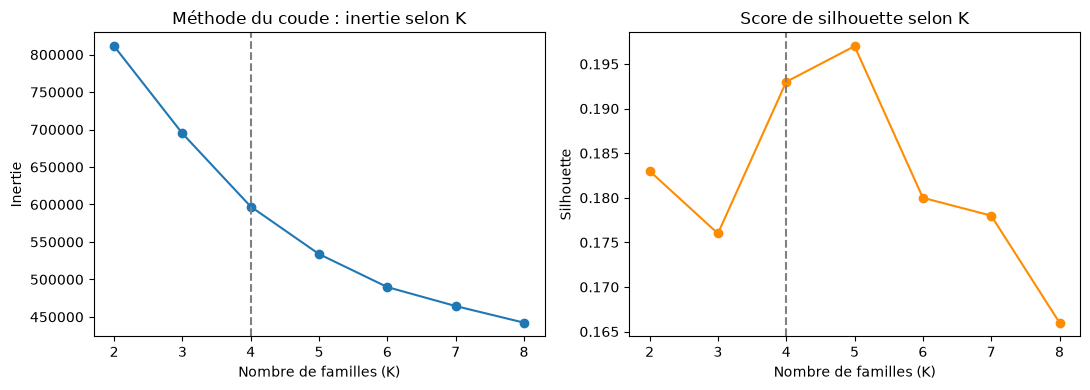

In [80]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(choix_k.index, choix_k["inertie"], marker="o")
axes[0].set_title("Méthode du coude : inertie selon K")
axes[0].set_xlabel("Nombre de familles (K)")
axes[0].set_ylabel("Inertie")
axes[1].plot(choix_k.index, choix_k["silhouette"], marker="o", color="darkorange")
axes[1].set_title("Score de silhouette selon K")
axes[1].set_xlabel("Nombre de familles (K)")
axes[1].set_ylabel("Silhouette")
for ax in axes:
    ax.axvline(4, color="grey", linestyle="--")
plt.tight_layout()
plt.show()

**Décision : K = 4.** La silhouette remonte nettement à K = 4 (0,193, contre 0,176 à K = 3). K = 5 fait à peine mieux (0,197), mais ajoute une famille de plus, plus difficile à interpréter. Au-delà, la silhouette baisse et l'inertie ne diminue presque plus.

**Limite :** une silhouette proche de 0,2 signifie que les familles se chevauchent. Il s'agit de tendances d'usage, et non de groupes nettement séparés.

## 6. Modèle final et stabilité

Nous vérifions la stabilité en relançant K-means avec trois autres graines aléatoires. L'**ARI** compare deux découpages : 1 signifie qu'ils sont identiques, 0 qu'ils ne se ressemblent pas plus que le hasard.

In [81]:
K = 4
modele = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=10).fit(X)
df["famille"] = modele.labels_

for graine in [1, 7, 123]:
    autre = KMeans(n_clusters=K, random_state=graine, n_init=10).fit(X)
    print(f"Graine {graine} : ARI = {adjusted_rand_score(modele.labels_, autre.labels_):.3f}")

Graine 1 : ARI = 0.977
Graine 7 : ARI = 0.982
Graine 123 : ARI = 0.995


In [82]:
centres = pd.DataFrame(modele.cluster_centers_, columns=STYLE).round(2)
centres

,part_reels,part_messages,part_explore,taux_clic_pub,ratio_abonnes
0,0.89,-0.08,-0.87,-0.02,-0.35
1,0.01,0.02,-0.01,-0.00,1.93
2,-0.11,-0.86,0.90,0.04,-0.34
3,-0.88,0.94,0.07,-0.02,-0.34


In [83]:
TRAITS = {"part_reels": "Adeptes des Reels", "part_messages": "Messagers",
          "part_explore": "Explorateurs", "ratio_abonnes": "Comptes très suivis"}
NOMS = {i: TRAITS[centres.loc[i, list(TRAITS)].idxmax()] for i in centres.index}
print(NOMS)

df["nom_famille"] = df["famille"].map(NOMS)
(df["nom_famille"].value_counts(normalize=True) * 100).round(1)

{0: 'Adeptes des Reels', 1: 'Comptes très suivis', 2: 'Explorateurs', 3: 'Messagers'}


nom_famille
Adeptes des Reels      30.4
Messagers              27.3
Explorateurs           27.3
Comptes très suivis    15.0
Name: proportion, dtype: float64

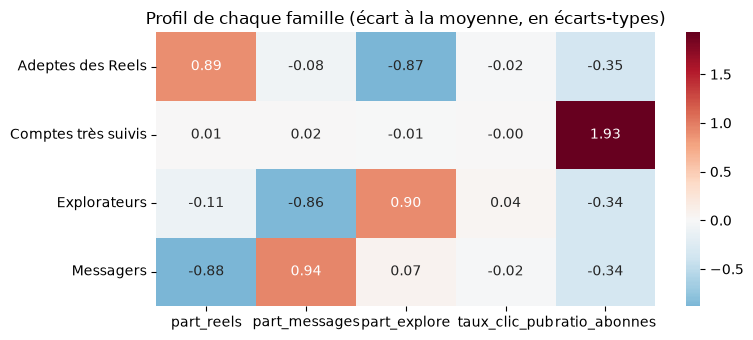

In [84]:
plt.figure(figsize=(8, 3.5))
sns.heatmap(centres.rename(index=NOMS), annot=True, cmap="RdBu_r", center=0, fmt=".2f")
plt.title("Profil de chaque famille (écart à la moyenne, en écarts-types)")
plt.tight_layout()
plt.show()

**Stabilité.** L'ARI dépasse 0,97 pour les trois graines : les familles ne dépendent pas du hasard de l'initialisation.

**Les 4 familles**, nommées automatiquement d'après leur trait le plus marqué :
- **Adeptes des Reels (30,4 %)** : beaucoup de Reels, peu d'Explorer ;
- **Explorateurs (27,3 %)** : beaucoup d'Explorer, peu de messages ;
- **Messagers (27,3 %)** : beaucoup de messages, peu de Reels ;
- **Comptes très suivis (15,0 %)** : bien plus d'abonnés que d'abonnements.

Le taux de clic publicitaire est identique dans les quatre familles (valeurs proches de 0) : il ne distingue personne.

## 7. Description des familles

Les colonnes de bien-être entrent en jeu **seulement maintenant**, pour décrire les familles déjà construites. L'âge, le genre et le pays servent à vérifier qu'aucune famille ne concentre un groupe protégé.

In [85]:
description = df.groupby("nom_famille")[DECRIRE].mean().round(2)
description.insert(0, "taille_%", (df["nom_famille"].value_counts(normalize=True) * 100).round(1))
description["mineurs_%"] = (df["age"].lt(18).groupby(df["nom_famille"]).mean() * 100).round(1)
description["femmes_%"] = (df["gender"].eq("Female").groupby(df["nom_famille"]).mean() * 100).round(1)

print(f"Ensemble du fichier : mineurs {df['age'].lt(18).mean() * 100:.1f} % | femmes {df['gender'].eq('Female').mean() * 100:.1f} %")
description

Ensemble du fichier : mineurs 9.4 % | femmes 47.9 %


,taille_%,daily_active_minutes_instagram,perceived_stress_score,self_reported_happiness,sleep_hours_per_night,mineurs_%,femmes_%
nom_famille,,,,,,,
Adeptes des Reels,30.4,184.57,19.65,5.55,7.00,9.1,48.4
Comptes très suivis,15.0,191.96,20.32,5.46,6.99,9.5,47.6
Explorateurs,27.3,198.64,20.87,5.33,7.00,9.6,47.7
Messagers,27.3,181.58,19.43,5.60,7.00,9.3,47.9


In [86]:
pays = pd.crosstab(df["country"], df["nom_famille"], normalize="index") * 100
print("Écart maximal entre pays, en points, pour chaque famille :")
(pays.max() - pays.min()).round(1)

Écart maximal entre pays, en points, pour chaque famille :


nom_famille
Adeptes des Reels      1.1
Comptes très suivis    0.9
Explorateurs           1.7
Messagers              1.4
dtype: float64

**Lecture.** Les quatre familles ont un profil de bien-être presque identique : entre 182 et 199 minutes par jour, un stress compris entre 19,4 et 20,9, et 7 heures de sommeil partout. Les mineurs représentent entre 9,1 % et 9,6 % de chaque famille, pour 9,4 % dans l'ensemble du fichier. Les femmes représentent entre 47,6 % et 48,4 % de chaque famille, pour 47,9 % au total. D'un pays à l'autre, la part de chaque famille varie de moins de 2 points.

**Conclusion :** aucune famille ne cible un groupe protégé. C'est une bonne nouvelle sur le plan éthique, mais cela annonce aussi que les familles diront peu de chose du bien-être.

## 8. Valeur ajoutée par rapport au temps passé

Nous comparons deux découpages : nos 4 familles de style, et un découpage simple en 3 groupes de temps passé (usage faible, moyen, intensif). Le R² indique la part des écarts de stress que chaque découpage explique.

In [87]:
df["groupe_temps"] = pd.qcut(df["daily_active_minutes_instagram"], 3, labels=["usage faible", "usage moyen", "usage intensif"])

stress = df["perceived_stress_score"]
r2_familles = r2_score(stress, df.groupby("nom_famille")["perceived_stress_score"].transform("mean"))
r2_temps = r2_score(stress, df.groupby("groupe_temps", observed=True)["perceived_stress_score"].transform("mean"))
print(f"Part du stress expliquée par les 4 familles : {r2_familles:.1%}")
print(f"Part du stress expliquée par 3 groupes de temps passé : {r2_temps:.1%}")

pd.crosstab(df["nom_famille"], df["groupe_temps"], normalize="index").round(3) * 100

Part du stress expliquée par les 4 familles : 0.2%
Part du stress expliquée par 3 groupes de temps passé : 63.3%


groupe_temps,usage faible,usage moyen,usage intensif
nom_famille,,,
Adeptes des Reels,34.9,32.6,32.5
Comptes très suivis,32.4,33.3,34.3
Explorateurs,29.7,35.4,34.9
Messagers,35.9,32.2,31.9


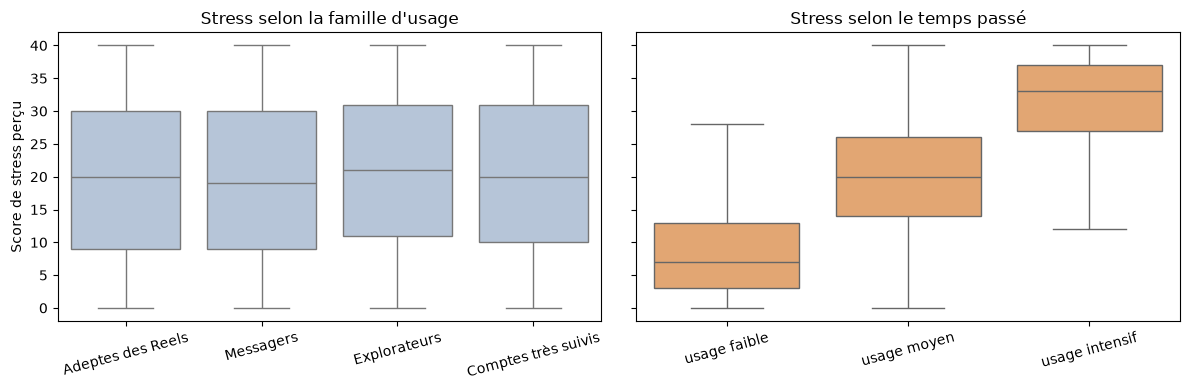

In [88]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
sns.boxplot(data=df, x="nom_famille", y="perceived_stress_score", ax=axes[0], color="lightsteelblue", showfliers=False)
axes[0].set_title("Stress selon la famille d'usage")
sns.boxplot(data=df, x="groupe_temps", y="perceived_stress_score", ax=axes[1], color="sandybrown", showfliers=False)
axes[1].set_title("Stress selon le temps passé")
for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
axes[0].set_ylabel("Score de stress perçu")
plt.tight_layout()
plt.show()

**Lecture.** Les 4 familles n'expliquent que **0,2 %** des écarts de stress, contre **63,3 %** pour un simple découpage en 3 groupes de temps passé. Le graphique le montre clairement : les boîtes sont alignées à gauche, mais montent nettement à droite. Chaque famille contient d'ailleurs environ un tiers d'usagers faibles, moyens et intensifs.

**Conclusion :** dans ces données, le stress dépend de **combien** on utilise Instagram, et non de **comment**. Les familles restent utiles pour adapter l'expérience (contenus, fonctionnalités), mais un dispositif de bien-être doit s'appuyer sur le temps passé.

In [89]:
systolique = df["blood_pressure_systolic"]
diastolique = df["blood_pressure_diastolic"]
pression_moyenne = diastolique + (systolique - diastolique) / 3

print("Corrélation systolique / diastolique :", round(systolique.corr(diastolique), 3))
print("Lignes médicalement impossibles (diastolique ≥ systolique) :", (diastolique >= systolique).sum())
print()
print("Corrélation de la pression artérielle moyenne avec :")
print("  le temps passé :", round(pression_moyenne.corr(df["daily_active_minutes_instagram"]), 3))
print("  le stress      :", round(pression_moyenne.corr(df["perceived_stress_score"]), 3))

Corrélation systolique / diastolique : -0.0
Lignes médicalement impossibles (diastolique ≥ systolique) : 3934

Corrélation de la pression artérielle moyenne avec :
  le temps passé : 0.002
  le stress      : 0.002


**Et la tension artérielle ?** Nous avons calculé une pression artérielle moyenne (diastolique + un tiers de l'écart avec la systolique), plutôt que de coller les deux valeurs dans un texte du type « 125,80 », qui ne permettrait aucun calcul.

**Résultat :** la tension n'a **aucun lien** avec l'usage d'Instagram (corrélation de 0,002 avec le temps passé comme avec le stress). Ce résultat doit être lu avec prudence : dans ce fichier, systolique et diastolique ne sont pas corrélées (0,00), et 3 934 lignes sont médicalement impossibles. Le générateur de la réplique synthétique n'a probablement pas conservé la structure réelle de la tension.

**Conclusion :** la tension n'est pas un indicateur de bien-être exploitable avec ces données. Comme toutes les données de santé, elle ne sert pas à construire les familles.

In [90]:
temps = df["daily_active_minutes_instagram"]
for cible in ["perceived_stress_score", "self_reported_happiness", "sleep_hours_per_night"]:
    print(f"{cible} : Pearson {temps.corr(df[cible]):.2f} | Spearman {temps.corr(df[cible], method='spearman'):.2f}")
print()
print(f"Âge et temps passé : {df['age'].corr(temps):.2f} | Âge et stress : {df['age'].corr(df['perceived_stress_score']):.2f}")
for colonnes in [["daily_active_minutes_instagram"], ["age"], ["daily_active_minutes_instagram", "age"]]:
    r2 = cross_val_score(LinearRegression(), df[colonnes], df["perceived_stress_score"], cv=5, scoring="r2").mean()
    print(f"R² du stress avec {colonnes} : {r2:.3f}")

perceived_stress_score : Pearson 0.83 | Spearman 0.84
self_reported_happiness : Pearson -0.37 | Spearman -0.36
sleep_hours_per_night : Pearson 0.00 | Spearman -0.00

Âge et temps passé : -0.20 | Âge et stress : -0.00
R² du stress avec ['daily_active_minutes_instagram'] : 0.696
R² du stress avec ['age'] : -0.000
R² du stress avec ['daily_active_minutes_instagram', 'age'] : 0.725


**Association, levier ou causalité ?** La corrélation de Spearman, qui travaille sur les rangs et résiste aux valeurs extrêmes, confirme les résultats de Pearson.

| Facteur | Association avec le stress | Levier actionnable ? | Causalité démontrée ? |
|---|---|---|---|
| Temps passé | forte (0,83 ; Spearman 0,84) | **oui** : rappels de pause, limites de temps | **non** |
| Âge | nulle sur le stress (0,00), mais lié au temps passé (−0,20) | non : on ne change pas l'âge | non |
| Style d'usage (familles) | quasi nulle (0,2 %) | oui, pour l'expérience | sans objet |
| Sommeil, tension | nulle (0,00) | non | non |

**Pourquoi nous ne parlons pas de causalité.** Les données sont relevées à une seule date : le stress peut pousser à passer plus de temps sur l'application autant que l'inverse. De plus, les plus jeunes passent plus de temps sans être plus stressés, et ajouter l'âge au temps passé améliore le modèle (R² de 0,696 à 0,725) : d'autres facteurs interviennent. Le temps passé est donc un **indicateur** et un **levier possible**, mais il n'est pas prouvé qu'agir dessus réduirait le stress. Seule une expérimentation (un test A/B des rappels de pause, par exemple) pourrait le montrer.

## 9. Critères de réussite

Nous vérifions chacun des sept critères annoncés dans la problématique.

In [91]:
ecart_pays = (pays.max() - pays.min()).max()

criteres = pd.DataFrame([
    ["Familles distinctes : silhouette ≥ 0,15", silhouette_score(X[echantillon], modele.labels_[echantillon]), 0.15, "min"],
    ["Familles stables : ARI le plus bas ≥ 0,90 (section 6)", 0.977, 0.90, "min"],
    ["Taille exploitable : plus petite famille ≥ 10 %", df["famille"].value_counts(normalize=True).min() * 100, 10, "min"],
    ["Pas de ciblage des mineurs : écart ≤ 2 points", description["mineurs_%"].max() - description["mineurs_%"].min(), 2, "max"],
    ["Pas de ciblage selon le genre : écart ≤ 2 points", description["femmes_%"].max() - description["femmes_%"].min(), 2, "max"],
    ["Pas de ciblage selon le pays : écart ≤ 3 points", ecart_pays, 3, "max"],
    ["Apport sur le bien-être : R² familles ≥ R² temps passé", r2_familles * 100, r2_temps * 100, "min"],
], columns=["critère", "valeur", "seuil", "sens"])

criteres["verdict"] = np.where(
    ((criteres["sens"] == "min") & (criteres["valeur"] >= criteres["seuil"])) |
    ((criteres["sens"] == "max") & (criteres["valeur"] <= criteres["seuil"])),
    "✅ atteint", "❌ non atteint")

criteres.drop(columns="sens").round(3)

,critère,valeur,seuil,verdict
0,"Familles distinctes : silhouette ≥ 0,15",0.193,0.150,✅ atteint
1,"Familles stables : ARI le plus bas ≥ 0,90 (sec...",0.977,0.900,✅ atteint
2,Taille exploitable : plus petite famille ≥ 10 %,15.048,10.000,✅ atteint
3,Pas de ciblage des mineurs : écart ≤ 2 points,0.500,2.000,✅ atteint
4,Pas de ciblage selon le genre : écart ≤ 2 points,0.800,2.000,✅ atteint
5,Pas de ciblage selon le pays : écart ≤ 3 points,1.739,3.000,✅ atteint
6,Apport sur le bien-être : R² familles ≥ R² tem...,0.248,63.273,❌ non atteint


**Bilan : 6 critères sur 7 sont atteints.** Les familles sont stables, de taille exploitable, et ne ciblent ni les mineurs, ni un genre, ni un pays. Leur séparation reste modeste (silhouette de 0,19).

Le critère non atteint est le plus important pour une étude sur le bien-être : les familles n'expliquent pas le stress. Nous le présentons comme un **résultat**, et non comme un échec. La segmentation par style d'usage ne doit pas servir à repérer des utilisateurs en difficulté.

In [92]:
y = df["perceived_stress_score"]
erreur_reference = mean_absolute_error(y, np.full(len(y), y.mean()))
erreur_familles = mean_absolute_error(y, df.groupby("famille")["perceived_stress_score"].transform("mean"))
erreur_temps = mean_absolute_error(y, cross_val_predict(LinearRegression(), df[["daily_active_minutes_instagram"]], y, cv=5))

print("Score de stress de 0 à 40. Erreur moyenne d'estimation :")
print(f"  référence (tout le monde = la moyenne) : {erreur_reference:.2f} points")
print(f"  avec la famille d'usage               : {erreur_familles:.2f} points")
print(f"  avec le temps passé                   : {erreur_temps:.2f} points")

Score de stress de 0 à 40. Erreur moyenne d'estimation :
  référence (tout le monde = la moyenne) : 10.24 points
  avec la famille d'usage               : 10.23 points
  avec le temps passé                   : 5.23 points


**Valeur pour le métier.** Sans aucune information, estimer le stress d'un utilisateur par la moyenne fait une erreur de 10,2 points sur 40. Connaître sa famille d'usage ne fait pas mieux (10,2 points). Connaître son temps passé **divise l'erreur par deux** (5,2 points), sans utiliser aucune donnée de santé.

**Pourquoi nous avons choisi le clustering plutôt que la prédiction.** Le département veut deux choses : des profils pour les équipes produit, et une mesure du lien avec le bien-être. La prédiction répond à la seconde : le temps passé suffit. Le clustering répond à la première : il produit des familles attribuables à 100 % des utilisateurs, à partir des seules données d'usage. Nous gardons donc les deux : les familles pour personnaliser l'expérience, le temps passé pour le bien-être.

## 10. Affecter un nouvel utilisateur

La fonction ci-dessous calcule les 5 ratios d'un nouvel utilisateur, applique **les mêmes bornes et la même standardisation** que pour l'entraînement, puis demande au modèle sa famille. Elle n'utilise que des données qu'Instagram détient pour tous ses utilisateurs. La démonstration porte uniquement sur des **profils fictifs**.

In [93]:
def affecter_famille(utilisateur):
    temps = (utilisateur["time_on_feed_per_day"] + utilisateur["time_on_explore_per_day"]
             + utilisateur["time_on_messages_per_day"] + utilisateur["time_on_reels_per_day"])
    ratios = pd.DataFrame([{
        "part_reels": utilisateur["time_on_reels_per_day"] / temps,
        "part_messages": utilisateur["time_on_messages_per_day"] / temps,
        "part_explore": utilisateur["time_on_explore_per_day"] / temps,
        "taux_clic_pub": utilisateur["ads_clicked_per_day"] / (utilisateur["ads_viewed_per_day"] + 1),
        "ratio_abonnes": utilisateur["followers_count"] / (utilisateur["following_count"] + 1),
    }])
    ratios = ratios.clip(lower=borne_basse, upper=borne_haute, axis=1)
    numero = modele.predict(scaler.transform(ratios))[0]
    return NOMS[numero]

In [94]:
base = {"ads_clicked_per_day": 1, "ads_viewed_per_day": 20, "followers_count": 300, "following_count": 500}

profils_fictifs = {
    "Profil A (fan de vidéos courtes)": {**base, "time_on_feed_per_day": 40, "time_on_explore_per_day": 10, "time_on_messages_per_day": 15, "time_on_reels_per_day": 60},
    "Profil B (grand bavard)":          {**base, "time_on_feed_per_day": 40, "time_on_explore_per_day": 20, "time_on_messages_per_day": 45, "time_on_reels_per_day": 15},
    "Profil C (curieux)":               {**base, "time_on_feed_per_day": 40, "time_on_explore_per_day": 40, "time_on_messages_per_day": 10, "time_on_reels_per_day": 30},
    "Profil D (créatrice populaire)":   {**base, "time_on_feed_per_day": 40, "time_on_explore_per_day": 20, "time_on_messages_per_day": 20, "time_on_reels_per_day": 30,
                                         "followers_count": 5000, "following_count": 1500},
}

for nom, profil in profils_fictifs.items():
    print(f"{nom} → {affecter_famille(profil)}")

Profil A (fan de vidéos courtes) → Adeptes des Reels
Profil B (grand bavard) → Messagers
Profil C (curieux) → Explorateurs
Profil D (créatrice populaire) → Comptes très suivis


## 10 bis. Protection des données

**1. Les données de l'étude.** Le fichier est une réplique synthétique. Il ne contient ni nom, ni identifiant Instagram réel : la colonne `user_id` est une numérotation de 1 à 200 000. L'équipe considère donc ces données comme anonymes au sens du considérant 26 du RGPD. Par précaution, et parce que l'équipe vie privée ne garantit pas qu'aucun utilisateur réel n'ait été reproduit, nous appliquons malgré tout trois règles : aucune ligne individuelle affichée, aucun résultat isolant une poignée d'utilisateurs, et des données de santé utilisées uniquement pour décrire les familles.

**2. Le déploiement sur de vrais utilisateurs.** Nos recommandations s'appliqueront à des utilisateurs réels, identifiables par Instagram. Le RGPD (Union européenne) et l'UK GDPR (Royaume-Uni) s'appliquent alors pleinement :
- **variables autorisées pour cibler :** les 5 ratios de style uniquement ;
- **variables interdites pour construire les segments :** la santé (article 9 : stress, sommeil, tension, IMC) et la vie privée (revenus, emploi, famille) ; l'âge, le genre et le pays servent seulement à vérifier ;
- **une famille révèle-t-elle la santé ?** Non : elle n'explique que 0,2 % du stress. En revanche, un classement par temps passé la révèle indirectement (63 %). Il doit être réservé à la prévention, avec un consentement explicite, et jamais à la publicité ;
- **consentement :** les volontaires ont accepté une étude sur le bien-être, pas un ciblage. Tout usage commercial exige un nouveau consentement, spécifique ;
- **mineurs :** aucune publicité fondée sur le profilage (Digital Services Act) ; au Royaume-Uni, application de l'Age Appropriate Design Code. 227 comptes créés sous l'âge minimal ont été retirés, et 671 Australiens de moins de 16 ans doivent être exclus de tout ciblage ;
- **avant tout déploiement :** une analyse d'impact (AIPD), car le traitement combine profilage à grande échelle, possible déduction de la santé et présence de mineurs.

**3. Le Code de la santé publique.** L'étude n'a aucune visée de soin ni de diagnostic : l'hébergement certifié HDS ne s'impose pas. L'équipe s'engage à ne jamais revendre ces indicateurs, ni à les utiliser pour du ciblage publicitaire.

## 11. Limites et conclusion

**Limites**
- **Association n'est pas causalité :** les données sont relevées à une seule date. Le lien entre temps passé et stress ne dit pas lequel provoque l'autre.
- **Du panel à tous les utilisateurs :** dans la réplique, tous les utilisateurs ont des données de bien-être. En réalité, seuls les volontaires du panel en auront, et ils ne représentent peut-être pas l'ensemble des utilisateurs.
- **De la réplique aux utilisateurs réels :** plusieurs incohérences trahissent les données synthétiques (628 utilisateurs cliquent sur plus de publicités qu'ils n'en voient, 3 934 tensions impossibles, un écart de 34 minutes entre les temps, une année de création du compte peu fiable).
- **Le style d'usage :** des études suggèrent que la manière d'utiliser les réseaux sociaux compterait plus que la durée. Nos données montrent l'inverse : soit cet effet est faible, soit la réplique ne l'a pas conservé.
- **Des familles qui se chevauchent :** avec une silhouette de 0,19, ce sont des tendances, et non des groupes étanches.

**Conclusion.** Nous obtenons 4 familles d'usage stables et éthiquement neutres : Adeptes des Reels, Explorateurs, Messagers et Comptes très suivis. Elles permettent d'adapter l'expérience Instagram selon la manière d'utiliser l'application. En revanche, elles n'expliquent pas le bien-être : le stress dépend du temps passé, qui en explique 70 % et divise par deux l'erreur d'estimation.

**Recommandation :** utiliser les familles pour personnaliser l'expérience, et le temps passé pour tout dispositif de prévention, avec un consentement explicite et après une analyse d'impact.